pineline คร่าวๆ เราเอาไฟล์ 3D มาแปลงเป็นจุดซึ่งก็คือ point cloud และมีการเลือกจำนวนจุดที่จะสร้างขึ้นอยู่กับความสามารถในการเทรนของเรา เสร็จแล้วเราจะแปลงไฟล์พวกนั้นที่เป็นจุดแล้วให้เป็นรูปแบบที่ ai สามารถเข้าใจได้เสร็จแล้วแเราก็เลือดโมเดลที่จะใช้ในการเรียนรู้ข้อมูล point cloud นั้นมาจะแปลงจุกในรูปแบบไหนซึ่งแตกต่างกันไปตามแต่ละโมเดล ซึ่งในที่นี้เลือกโมเดล DGCNN มาใช้ซึ่งนะที่นี้เนื่องจากข้อมูลมีเยอะและใช้เวลาเทรนนาน runtime ผมไม่พอจะเทรนให้ดูได้แค่ epoch เดียว และข้างล่างจะมีรูปแบบการทำที่ใช้ 2 โมเดล ในการพิดิกคำตอบซึ่งวัดจากว่าความมั่นใจของใครมากกว่ากันแล้วนำมาตอบแต่ ru time ไม่พอเทรนจึงได้มีแต่โครงคร่าวๆไว้
- ตอนแรกผมเลือกเอามา 1024 จุดแต่ runtime ไม่ไหวเลยไปลดเหลือแค่ 512 จุดตอนหลัง
- ผมอาจจะยังไม่ได้เข้าใจโดยละเอียดมากในรูปแบบการแปลงข้อมูลว่าจะมีผลอะไรยังไงบ้างถ้าแต่งตรงไหนแต่พร้อมเรียนรู้ครับ

# Set

## Mount Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Dowaload Data set

In [ ]:
!pip install -q kaggle
import shutil, os, zipfile

# ✅ 1) ตั้งค่า kaggle.json
!mkdir -p ~/.kaggle
shutil.copy("/content/drive/MyDrive/kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 600)

# ✅ 2) ดาวน์โหลด dataset
!kaggle datasets download -d balraj98/modelnet40-princeton-3d-object-dataset

# ✅ 3) แตก zip ไปยัง Drive
dataset_zip = "modelnet40-princeton-3d-object-dataset.zip"
target_path = "/content/drive/MyDrive/Pointnet"
os.makedirs(target_path, exist_ok=True)

if os.path.exists(dataset_zip):
    with zipfile.ZipFile(dataset_zip, 'r') as zip_ref:
        zip_ref.extractall(target_path)
    print("✅ แตกไฟล์ zip เสร็จแล้ว")
else:
    print("❌ ไม่พบไฟล์ zip")

print("✅ เสร็จสิ้น โหลด ModelNet40 เรียบร้อยแล้ว")


Dataset URL: https://www.kaggle.com/datasets/balraj98/modelnet40-princeton-3d-object-dataset
License(s): other
 98% 1.87G/1.91G [00:18<00:00, 299MB/s]
100% 1.91G/1.91G [00:18<00:00, 111MB/s]
✅ แตกไฟล์ zip เสร็จแล้ว
✅ เสร็จสิ้น โหลด ModelNet40 เรียบร้อยแล้ว


## import libraries

In [ ]:
# ✅ ติดตั้ง open3d หากยังไม่ได้ติดตั้ง
!pip install -q open3d

# === Import libraries ===
import os
import math
import random
import numpy as np
import open3d as o3d
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import confusion_matrix
from tqdm import tqdm

# ✅ ตรวจสอบอุปกรณ์ที่ใช้
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {DEVICE}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.7/447.7 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 77.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 66.3 MB/s eta 0:00:00
✅ Using device: cuda


# Data

## Check and Plot Data (.off)


**`load_off_point_cloud`**

ฟังก์ชันนี้ทำหน้าที่เตรียมข้อมูลดิบให้พร้อมใช้งาน โดยแบ่งเป็น 3 ขั้นตอนหลัก ดังนี้:

 1️⃣ **โหลดไฟล์ (Load Mesh)**
* ใช้คำสั่ง `o3d.io.read_triangle_mesh(off_path)` เพื่ออ่านไฟล์โมเดล 3 มิติ (Mesh) เข้ามา
*  **ระบบป้องกัน:** มีเช็ค `if mesh.is_empty()` หากไฟล์เสียหรืออ่านไม่ได้ จะแจ้งเตือนทันที

 2️⃣ **แปลงเป็นจุด (Sampling)**
* **หลักการ:** ปกติไฟล์ `.off` จะเก็บข้อมูลเป็น **"พื้นผิวสามเหลี่ยม" (Triangles)** แต่โมเดล AI ส่วนใหญ่อยากได้ข้อมูลเป็น **"จุด" (Points)**
* **วิธีการ:** ใช้คำสั่ง `mesh.sample_points_uniformly(...)` เพื่อสุ่มจุดบนพื้นผิวของโมเดลออกมาตามจำนวนที่กำหนด (`num_points`)
    * *ในโค้ดนี้กำหนดไว้ที่ **1024 จุด*** เพราะเป็นค่าที่กำลังดีในการเทรน

 3️⃣ **จัดระเบียบข้อมูล (Normalization)**
>  **Note:** ส่วนนี้สำคัญมากสำหรับการเทรน AI เพื่อให้ข้อมูลมีมาตรฐานเดียวกัน

* **Centering (ย้ายเข้ากลาง):**
    * หาจุดกึ่งกลางของวัตถุ แล้วย้ายวัตถุมาไว้ที่จุด `(0, 0, 0)`
    * `points -= center` : เพื่อให้โมเดลเรียนรู้รูปร่างโดยไม่สับสนเรื่องตำแหน่ง
* **Scaling (ปรับขนาด):**
    * ย่อ/ขยายขนาดของวัตถุให้อยู่ในช่วง **[-1, 1]**
    * `points /= (max_range / 2.0)` : เพื่อให้ขนาดของวัตถุทุกชิ้นใน Dataset มีสเกลเท่ากัน ไม่ว่าของจริงจะเป็นเครื่องบินลำใหญ่หรือถ้วยใบเล็ก

In [ ]:
DATA_DIR = "/content/drive/MyDrive/Pointnet/ModelNet40"
NUM_POINTS = 1024

In [ ]:
def load_off_point_cloud(off_path, num_points=NUM_POINTS):
    """
    โหลด mesh จาก .off แล้ว sample point cloud ออกมาเป็น (num_points, 3)
    """
    mesh = o3d.io.read_triangle_mesh(off_path)
    if mesh.is_empty():
        raise ValueError(f"❌ ไม่สามารถโหลด mesh จาก {off_path}")

    # Sample points จากผิวของ mesh
    pcd = mesh.sample_points_uniformly(number_of_points=num_points)
    points = np.asarray(pcd.points, dtype=np.float32)

    # Normalize: ศูนย์กลางและสเกลให้พอดีในช่วง [-1, 1]
    min_coords = points.min(axis=0)
    max_coords = points.max(axis=0)
    center = (min_coords + max_coords) / 2.0
    points -= center  # ย้ายให้อยู่ตรงกลาง

    max_range = (max_coords - min_coords).max()
    if max_range > 0:
        points /= (max_range / 2.0)  # scale ให้พอดีใน cube [-1, 1]

    return points


# === ทดสอบโหลด class แรกของ dataset ===
classes = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
print(f"✅ พบทั้งหมด {len(classes)} classes:", classes[:5], "...")

sample_class = classes[0] if classes else None
if sample_class:
    train_dir = os.path.join(DATA_DIR, sample_class, "train")
    sample_files = [f for f in os.listdir(train_dir) if f.endswith(".off")]

    if sample_files:
        sample_file_path = os.path.join(train_dir, sample_files[0])
        pts = load_off_point_cloud(sample_file_path, num_points=NUM_POINTS)
        print(f"✅ Loaded point cloud shape: {pts.shape}, range: [{pts.min():.2f}, {pts.max():.2f}]")
    else:
        print("⚠️ ไม่พบ .off files ใน train folder")
else:
    print("⚠️ ไม่พบ class ใน dataset")


✅ พบทั้งหมด 40 classes: ['airplane', 'bathtub', 'bed', 'bench', 'bookshelf'] ...
✅ Loaded point cloud shape: (1024, 3), range: [-1.00, 1.00]


เนื่องจาก Data imbalance แต่เนื่องจากข้อมูลที่มีจำนวนน้อยที่สุดนั้นน้อยมากซึ่งจะกลายเป็นว่าข้อมูลในการเทรนจะน้อยเกินไป และ การเฉลี่ยหาตรงกลาง แล้ว Augment ให้เท่ากันก็อาจจะจะต้องให้ข้อมูลไม่เหมือนกันมากเกินไปจน bias จึงขอเลือกใช้ imbalance

🔢 Total classes: 40
📁 Total files: 12311

📊 File count per class:
- airplane             | Train: 626 | Test: 100 | Total: 726
- bathtub              | Train: 106 | Test:  50 | Total: 156
- bed                  | Train: 515 | Test: 100 | Total: 615
- bench                | Train: 173 | Test:  20 | Total: 193
- bookshelf            | Train: 572 | Test: 100 | Total: 672
- bottle               | Train: 335 | Test: 100 | Total: 435
- bowl                 | Train:  64 | Test:  20 | Total: 84
- car                  | Train: 197 | Test: 100 | Total: 297
- chair                | Train: 889 | Test: 100 | Total: 989
- cone                 | Train: 167 | Test:  20 | Total: 187
- cup                  | Train:  79 | Test:  20 | Total: 99
- curtain              | Train: 138 | Test:  20 | Total: 158
- desk                 | Train: 200 | Test:  86 | Total: 286
- door                 | Train: 109 | Test:  20 | Total: 129
- dresser              | Train: 200 | Test:  86 | Total: 286
- flower_pot         

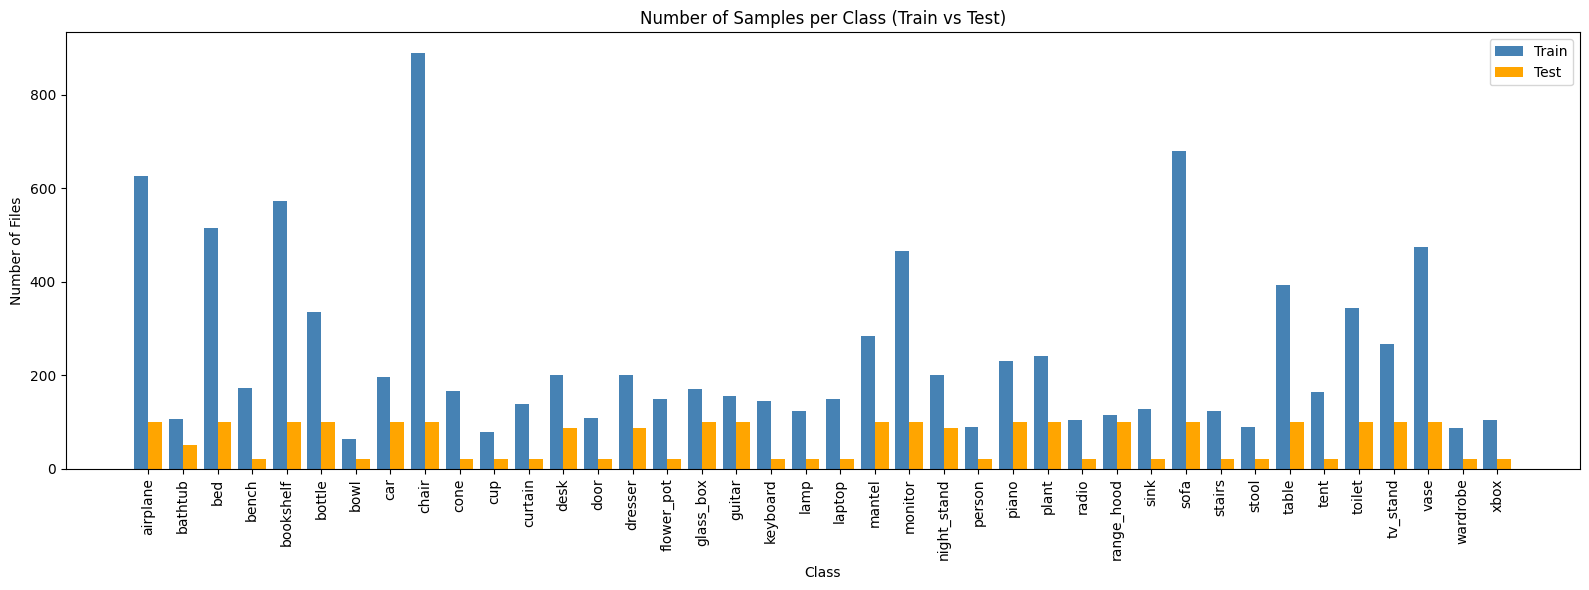

In [ ]:
# ✅ ปิด warning เรื่องฟอนต์
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

# ✅ Path หลัก
DATA_DIR = "/content/drive/MyDrive/Pointnet/ModelNet40"

# ✅ ดึงชื่อคลาสทั้งหมด (ชื่อโฟลเดอร์)
class_names = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
num_classes = len(class_names)
print(f"🔢 Total classes: {num_classes}")

# ✅ นับจำนวนไฟล์ในแต่ละคลาส แยกเป็น train/test
train_counts = []
test_counts = []

for cls in class_names:
    cls_dir = os.path.join(DATA_DIR, cls)

    train_dir = os.path.join(cls_dir, "train")
    test_dir = os.path.join(cls_dir, "test")

    train_files = [f for f in os.listdir(train_dir) if f.endswith('.off') or f.endswith('.npy')] if os.path.exists(train_dir) else []
    test_files = [f for f in os.listdir(test_dir) if f.endswith('.off') or f.endswith('.npy')] if os.path.exists(test_dir) else []

    train_counts.append(len(train_files))
    test_counts.append(len(test_files))

# ✅ รวมจำนวนไฟล์ทั้งหมด
total_files = sum(train_counts) + sum(test_counts)
print(f"📁 Total files: {total_files}")
print("\n📊 File count per class:")
for i, cls in enumerate(class_names):
    print(f"- {cls:20s} | Train: {train_counts[i]:3d} | Test: {test_counts[i]:3d} | Total: {train_counts[i] + test_counts[i]}")

# ✅ วาดกราฟแบบแท่งคู่
x = range(num_classes)
plt.figure(figsize=(16, 6))
plt.bar(x, train_counts, width=0.4, label='Train', color='steelblue')
plt.bar([i + 0.4 for i in x], test_counts, width=0.4, label='Test', color='orange')
plt.xticks([i + 0.2 for i in x], class_names, rotation=90)
plt.title("Number of Samples per Class (Train vs Test)")
plt.xlabel("Class")
plt.ylabel("Number of Files")
plt.legend()
plt.tight_layout()
plt.show()

**ขั้นตอนการเตรียมและแสดงผลข้อมูล (Data Visualization Workflow)**

กระบวนการทำงานของโค้ดส่วนนี้แบ่งออกเป็น 4 ขั้นตอนหลัก :

---

**1. สแกนหา Class ทั้งหมด**
* ระบบจะทำการค้นหาโฟลเดอร์ทั้งหมดใน Directory
* เก็บรายชื่อคลาสทั้งหมดไว้ในตัวแปร `classes`
* ทำการนับจำนวนว่ามีทั้งหมดกี่หมวดหมู่

**2. รวบรวมตัวแทนจากทุกคลาส**
* **Loop:** โค้ดจะวนเข้าไปใน **ทุกๆ คลาส**
* **Sampling:** ในแต่ละคลาส จะสุ่มหยิบไฟล์ `.off` มา **1 ไฟล์**
* **Collection:** เก็บไฟล์ที่สุ่มได้ใส่ตะกร้า (List) ที่ชื่อว่า `samples` เอาไว้
* **ผลลัพธ์:** เราจะได้ลิสต์รายชื่อไฟล์ตัวแทนของทุกคลาสเตรียมไว้เลือกใช้งาน

**3. แปลงร่างข้อมูล (Mesh ⮕ Point Cloud)**
> **ส่วนนี้คือหัวใจสำคัญ:**
> คือการแปลงข้อมูลดิบแบบแผ่นสามเหลี่ยม (**Mesh**) ให้เป็นกลุ่มจุด (**Point Cloud**)

* สุ่มหยิบตัวอย่างมา 1 ชิ้น
* ทำการ Sample จุดจำนวน **768 จุด** (ซึ่งเป็น format ที่ PointNet ต้องการ)
* ตัวแปร `pts` จะเก็บพิกัด `(x, y, z)` ของจุดเหล่านั้นไว้

**4. วาดกราฟ 3 มิติ (Visualization)**
ใช้ Library `matplotlib` วาดจุดทั้ง 768 จุดลงในกราฟ 3D โดยมีการตั้งค่าดังนี้:
* `c=pts[:,2]` : กำหนด **สีของจุดตามความสูง (แกน Z)** เพื่อให้ดูมิติความลึกง่ายขึ้น
* `cmap='jet'` : ใช้โทนสี **ร้อน-เย็น** (สีน้ำเงินคือต่ำ 🔵 $\to$ สีแดงคือสูง 🔴)

✅ พบทั้งหมด 40 คลาส


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


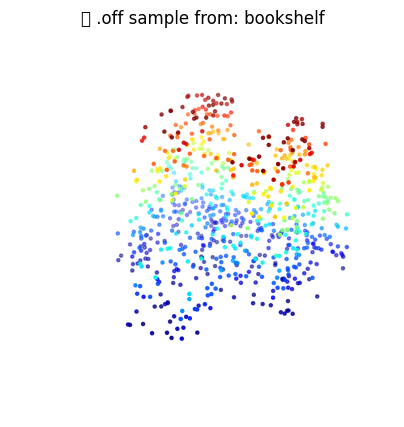

In [ ]:
  OFF_DIR = "/content/drive/MyDrive/Pointnet/ModelNet40"
  classes = sorted([d for d in os.listdir(OFF_DIR) if os.path.isdir(os.path.join(OFF_DIR, d))])
  print(f"✅ พบทั้งหมด {len(classes)} คลาส")

  # ✅ ดึงไฟล์ .off แบบสุ่มจาก train folder
  samples = []
  for cls in classes:
      train_dir = os.path.join(OFF_DIR, cls, 'train')
      if os.path.exists(train_dir):
          files = [f for f in os.listdir(train_dir) if f.endswith('.off')]
          if files:
              samples.append(os.path.join(train_dir, np.random.choice(files)))

  # ✅ โหลดและ plot
  sample_file = np.random.choice(samples)
  mesh = o3d.io.read_triangle_mesh(sample_file)
  pcd = mesh.sample_points_uniformly(number_of_points=768)
  pts = np.asarray(pcd.points)
  cls_name = sample_file.split("/")[-3]

  fig = plt.figure(figsize=(5,5))
  ax = fig.add_subplot(111, projection='3d')
  ax.scatter(pts[:,0], pts[:,1], pts[:,2], s=5, c=pts[:,2], cmap='jet')
  ax.set_title(f"🔍 .off sample from: {cls_name}")
  ax.set_axis_off()
  plt.show()


## Augment data (not use in DGCNN nomal Model)


**คำอธิบายโค้ด: Data Augmentation Pipeline **

โค้ดชุดนี้ทำหน้าที่เตรียมข้อมูลและเพิ่มจำนวนข้อมูล (Data Augmentation) เพื่อให้โมเดลเรียนรู้ได้ดียิ่งขึ้น โดยมีรายละเอียดการทำงาน 4 ส่วนหลัก ดังนี้:

---

**1. `fix_off_header(file_path)`: ช่างซ่อมไฟล์**
* **ปัญหา:** ไฟล์ `.off` ใน Dataset สาธารณะบางไฟล์มักมีบั๊กที่บรรทัดแรก (เช่น เขียนติดกันว่า `OFF123` แทนที่จะเป็น `OFF` แล้วขึ้นบรรทัดใหม่)
* **หน้าที่:** เปิดไฟล์เช็ค ถ้าเจอหัวไฟล์ติดกัน จะแก้ให้อยู่ในรูปแบบที่ถูกต้องทันที เพื่อป้องกันโปรแกรม Error ขณะอ่านไฟล์

**2. `load_off_point_cloud(...)`: ตัวโหลดและปรับมาตรฐาน**
ทำหน้าที่แปลงไฟล์โมเดลให้เป็นรูปแบบที่พร้อมใช้งาน:
> อ่านไฟล์ Mesh $\rightarrow$ สุ่มจุด (`NUM_POINTS`) $\rightarrow$ ย้ายมาตรงกลาง (Center) $\rightarrow$ ปรับขนาดให้อยู่ในช่วง [-1, 1] (Normalize)

**3. `augment_point_cloud(points)`: ตัวปั่นข้อมูล (Data Augmentation)**
นี่คือ **ส่วนสำคัญ** ที่ช่วยให้โมเดลฉลาดขึ้น โดยการดัดแปลงข้อมูลเล็กน้อยเพื่อให้เรียนรู้ได้หลากหลาย:
* **🔄 การหมุน (Rotation):** สุ่มมุม `theta` (0-360°) แล้วหมุนวัตถุรอบแกน Z (แนวตั้ง) เหมือนเราหมุนเก้าอี้ดูรอบๆ
* **📏 การย่อ/ขยาย (Scaling):** สุ่มตัวเลขระหว่าง 0.8 ถึง 1.25 เพื่อขยายหรือย่อขนาดวัตถุเล็กน้อย
* **🎲 การสุ่มทิ้งจุด (Point Dropout):**
    * มีโอกาส 50% ที่จะ **"ลบจุดบางจุดทิ้ง"** (Drop)
    * **สำคัญ:** เมื่อลบจุดไปแล้ว จำนวนจุดจะไม่ครบ 1024 โค้ดส่วนนี้จึงทำการ **"สุ่มหยิบจุดที่เหลือมาแปะเพิ่ม"** (Duplicate) เพื่อให้ข้อมูลกลับมาครบ 1024 จุดเท่าเดิม (รักษารูปทรง Matrix ให้คงที่)

**4. `augment_and_save_dataset(...)`: ผู้จัดการโรงงาน**
ฟังก์ชันนี้จะคอยควบคุมกระบวนการทั้งหมดและวนลูปทำกับทุกไฟล์:
1.  **วนลูปทุกคลาส:** เข้าไปทีละโฟลเดอร์
2.  **ซ่อมและโหลด:** เรียกใช้ฟังก์ชันในข้อ 1 และ 2
3.  **บันทึกตัวต้นฉบับ:** เซฟข้อมูลดิบเป็นไฟล์ `.npy` (ตั้งชื่อ `_orig`)
4.  **สร้างตัว Augment:** วนลูปตามจำนวน `num_augments` (เช่น 2 รอบ)
    * เรียกฟังก์ชันปั่นข้อมูล (ข้อ 3)
    * บันทึกไฟล์ที่ปั่นแล้วเป็น `.npy` (ตั้งชื่อ `_aug1`, `_aug2`)

---

**ตัวอย่างผลลัพธ์**
สมมติคุณมีไฟล์เก้าอี้ 1 ไฟล์ชื่อ `chair_001.off` หลังจากรันโค้ดนี้ ในโฟลเดอร์ปลายทาง คุณจะได้ไฟล์ `.npy` 3 ไฟล์:
* `chair_001_orig.npy` (เก้าอี้หน้าตรง)
* `chair_001_aug1.npy` (เก้าอี้เอียงซ้ายนิดหน่อย ใหญ่ขึ้น)
* `chair_001_aug2.npy` (เก้าอี้หันหลัง เล็กลง)

**ข้อดีของวิธีนี้**
* **เพิ่มข้อมูล 3 เท่า:** จาก 1 ไฟล์ กลายเป็น 3 ไฟล์ (ช่วยแก้ปัญหาข้อมูลน้อย)
* **โหลดเร็ว:** ไฟล์ `.npy` ของ NumPy โหลดเร็วกว่าการอ่าน `.off` แล้วแปลงใหม่ทุกรอบอย่างมหาศาลครับ

In [ ]:
# ✅ Config
DATA_DIR = "/content/drive/MyDrive/Pointnet/ModelNet40"
AUGMENTED_DIR = "/content/drive/MyDrive/Pointnet/ModelNet40_Augmented"
NUM_POINTS = 1024

# ✅ แก้ header OFF ที่ผิดรูปแบบให้ถูกต้อง
def fix_off_header(file_path):
    with open(file_path, 'r') as f:
        lines = f.readlines()

    if not lines[0].strip() == 'OFF':
        if lines[0].strip().startswith('OFF'):
            parts = lines[0].strip()[3:].strip().split()
            lines = ['OFF\n', ' '.join(parts) + '\n'] + lines[1:]
            with open(file_path, 'w') as f:
                f.writelines(lines)

# ✅ ฟังก์ชันโหลด point cloud จาก .off และ normalize
def load_off_point_cloud(off_path, num_points=NUM_POINTS):
    mesh = o3d.io.read_triangle_mesh(off_path)
    if mesh.is_empty():
        raise ValueError(f"Failed to load mesh from {off_path}")
    pcd = mesh.sample_points_uniformly(number_of_points=num_points)
    points = np.asarray(pcd.points, dtype=np.float32)
    min_coords = points.min(axis=0)
    max_coords = points.max(axis=0)
    center = (min_coords + max_coords) / 2.0
    points -= center
    max_range = (max_coords - min_coords).max()
    if max_range > 0:
        points /= (max_range / 2.0)
    return points

# ✅ ฟังก์ชัน augment
def augment_point_cloud(points):
    theta = np.random.uniform(0, 2 * math.pi)
    rot_matrix = np.array([[math.cos(theta), -math.sin(theta), 0],
                           [math.sin(theta),  math.cos(theta), 0],
                           [0, 0, 1]], dtype=np.float32)
    points = points.dot(rot_matrix.T)
    scale = np.random.uniform(0.8, 1.25)
    points *= scale
    if np.random.rand() < 0.5:
        drop_ratio = np.random.uniform(0.0, 0.1)
        num_drop = int(drop_ratio * points.shape[0])
        if num_drop > 0:
            drop_idx = np.random.choice(points.shape[0], num_drop, replace=False)
            keep_mask = np.ones(points.shape[0], dtype=bool)
            keep_mask[drop_idx] = False
            points_kept = points[keep_mask]
            num_kept = points_kept.shape[0]
            dup_idx = np.random.choice(num_kept, num_drop, replace=(num_drop > num_kept))
            points_dup = points_kept[dup_idx]
            points = np.concatenate([points_kept, points_dup], axis=0)
    return points

# ✅ ฟังก์ชันหลักสำหรับ augment และบันทึกเป็น .npy
def augment_and_save_dataset(root_dir, output_root, split="train", num_points=1024, num_augments=2):
    os.makedirs(output_root, exist_ok=True)
    classes = sorted([d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))])
    for cls_name in classes:
        input_dir = os.path.join(root_dir, cls_name, split)
        if not os.path.isdir(input_dir):
            continue
        output_dir = os.path.join(output_root, cls_name)
        os.makedirs(output_dir, exist_ok=True)

        for fname in os.listdir(input_dir):
            if fname.endswith(".off"):
                file_path = os.path.join(input_dir, fname)
                try:
                    fix_off_header(file_path)  # ✅ แก้ header ก่อนโหลด
                    orig_points = load_off_point_cloud(file_path, num_points)
                    base_name = os.path.splitext(fname)[0]
                    np.save(os.path.join(output_dir, f"{base_name}_orig.npy"), orig_points)

                    for i in range(num_augments):
                        aug_points = augment_point_cloud(orig_points)
                        np.save(os.path.join(output_dir, f"{base_name}_aug{i+1}.npy"), aug_points)
                except Exception as e:
                    print(f"❌ Error processing {file_path}: {e}")

# ✅ เรียกใช้งาน
augment_and_save_dataset(DATA_DIR, AUGMENTED_DIR, split="train", num_points=NUM_POINTS, num_augments=2)
print("✅ เสร็จสิ้น Augmentation แล้วบันทึกไฟล์ .npy ไปที่:", AUGMENTED_DIR)


✅ เสร็จสิ้น Augmentation แล้วบันทึกไฟล์ .npy ไปที่: /content/drive/MyDrive/Pointnet/ModelNet40_Augmented


## Check data .npy (not use in DGCNN nomal Model)

**คำอธิบายโค้ด: การตรวจสอบสรุปยอดข้อมูล (Data Inspection)**

หลังจากรันโค้ด Augmentation แล้ว ส่วนนี้จะทำหน้าที่ **เช็คผลลัพธ์** ว่าเรามีข้อมูลพร้อมเทรนจำนวนเท่าไหร่ และการกระจายตัวของข้อมูลเป็นอย่างไร โดยแบ่งการทำงานเป็น 3 ส่วนหลักครับ:

---

**1. สแกนและนับจำนวนไฟล์ (Counting)**
* **เป้าหมาย:** โค้ดจะเข้าไปสำรวจในโฟลเดอร์ `ModelNet40_Augmented`
* **สิ่งที่ทำ:**
    * อ่านรายชื่อคลาสทั้งหมด (เช่น `airplane`, `chair`)
    * เข้าไปนับไฟล์นามสกุล **`.npy`** (ไฟล์ที่แปลงและ Augment มาแล้ว) ในแต่ละโฟลเดอร์
    * เก็บยอดรวมเพื่อประเมินขนาดของ Dataset

**2. แสดงรายงานแบบข้อความ (Text Report)**
ระบบจะพิมพ์สรุปข้อมูลสำคัญออกมาทางหน้าจอ:
* **`Total classes`**: จำนวนประเภทวัตถุ (ควรได้ 40 คลาส)
* **`Total files`**: จำนวนไฟล์ข้อมูลทั้งหมด
    * *ข้อสังเกต:* ยอดรวมควรเยอะกว่าเดิม **3 เท่า** (ถ้าคุณตั้งค่า Augment ไว้ 2 แบบ + ต้นฉบับ 1)
* **`File count per class`**: รายการสรุปว่าแต่ละคลาสมีจำนวนกี่ไฟล์

**3. สร้างกราฟแท่ง (Visualization)**
ใช้ Library `matplotlib` วาดกราฟแท่งเพื่อดูภาพรวม:
* **แกน X:** ชื่อคลาส (โต๊ะ, ตู้, เตียง ฯลฯ)
* **แกน Y:** จำนวนไฟล์
* **✅ ประโยชน์:** เพื่อเช็ค **Data Imbalance (ความไม่สมดุลของข้อมูล)**

> **ข้อสังเกตสำคัญ:**
> ให้ดูความสูงของกราฟแต่ละแท่ง
> * ถ้ากราฟสูงต่ำไม่เท่ากันมาก (เช่น แท่ง 'เก้าอี้' สูงปรี๊ด แต่แท่ง 'ถ้วยกาแฟ' เตี้ยติดดิน)
> * แสดงว่าโมเดลอาจจะเก่งแต่เรื่องเก้าอี้ แต่ทายถ้วยกาแฟไม่ถูก
> * กราฟนี้ช่วยให้เรารู้ตัวและวางแผนรับมือก่อนเริ่มเทรนจริงครับ

🔢 Total classes: 40
📁 Total files: 29529

📊 File count per class:
- airplane             | Files: 1878
- bathtub              | Files: 318
- bed                  | Files: 1545
- bench                | Files: 519
- bookshelf            | Files: 1716
- bottle               | Files: 1005
- bowl                 | Files: 192
- car                  | Files: 591
- chair                | Files: 2667
- cone                 | Files: 501
- cup                  | Files: 237
- curtain              | Files: 414
- desk                 | Files: 600
- door                 | Files: 327
- dresser              | Files: 600
- flower_pot           | Files: 447
- glass_box            | Files: 513
- guitar               | Files: 465
- keyboard             | Files: 435
- lamp                 | Files: 372
- laptop               | Files: 447
- mantel               | Files: 852
- monitor              | Files: 1395
- night_stand          | Files: 600
- person               | Files: 264
- piano                | Fil

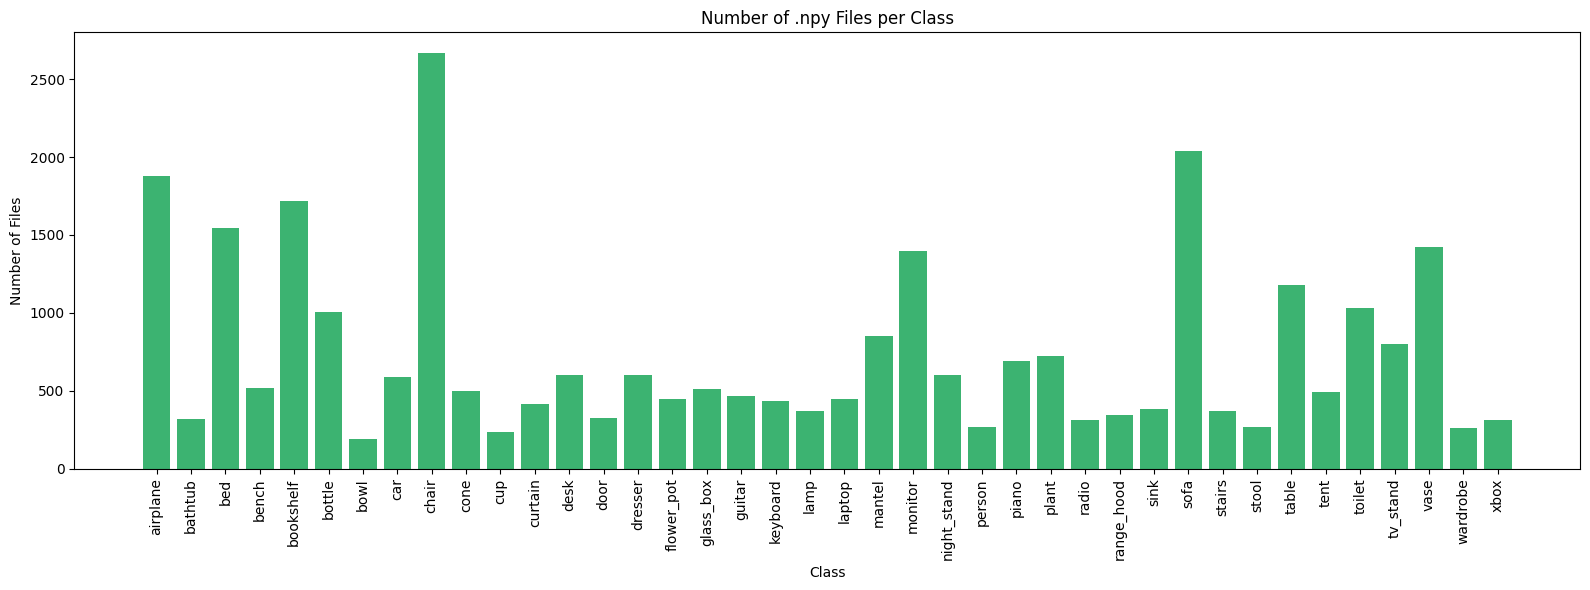

In [ ]:
# ✅ ปิด warning ฟอนต์
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

# ✅ Path หลัก
DATA_DIR = "/content/drive/MyDrive/Pointnet/ModelNet40_Augmented"

# ✅ ดึงชื่อคลาสทั้งหมด
class_names = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
num_classes = len(class_names)
print(f"🔢 Total classes: {num_classes}")

counts = []

# ✅ นับทุก .npy ไฟล์ในแต่ละคลาส
for cls in class_names:
    cls_dir = os.path.join(DATA_DIR, cls)
    files = [f for f in os.listdir(cls_dir) if f.endswith('.npy')] if os.path.exists(cls_dir) else []
    counts.append(len(files))

# ✅ รวม
total_files = sum(counts)
print(f"📁 Total files: {total_files}\n")

print("📊 File count per class:")
for i, cls in enumerate(class_names):
    print(f"- {cls:20s} | Files: {counts[i]}")

# ✅ วาดกราฟ
x = range(num_classes)
plt.figure(figsize=(16, 6))
plt.bar(x, counts, color='mediumseagreen')
plt.xticks(x, class_names, rotation=90)
plt.title("Number of .npy Files per Class")
plt.xlabel("Class")
plt.ylabel("Number of Files")
plt.tight_layout()
plt.show()


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


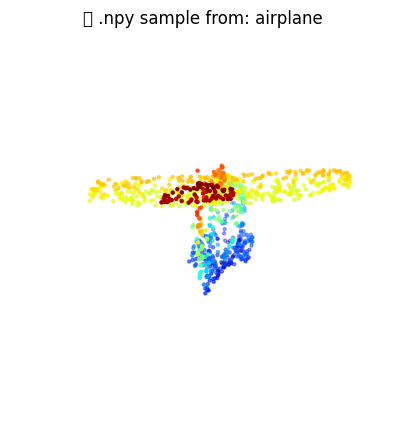

In [ ]:
# ✅ Path ไปยังโฟลเดอร์ที่มีไฟล์ .npy
NPY_DIR = "/content/drive/MyDrive/Pointnet/ModelNet40_Augmented"

# ✅ หาไฟล์ .npy ทั้งหมดในทุกคลาส
samples = []
class_names = []
for cls in sorted(os.listdir(NPY_DIR)):
    class_dir = os.path.join(NPY_DIR, cls)
    if not os.path.isdir(class_dir):
        continue
    for fname in os.listdir(class_dir):
        if fname.endswith(".npy"):
            samples.append(os.path.join(class_dir, fname))
            class_names.append(cls)

# ✅ เช็คว่าเจอไฟล์หรือไม่
if not samples:
    raise ValueError("❌ ไม่พบไฟล์ .npy ในโฟลเดอร์ที่กำหนด")

# ✅ เลือกไฟล์แบบสุ่ม
idx = np.random.randint(len(samples))
sample_path = samples[idx]
points = np.load(sample_path)
cls_name = class_names[idx]

# ✅ Plot 3D
fig = plt.figure(figsize=(5,5))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(points[:,0], points[:,1], points[:,2], s=5, c=points[:,2], cmap='jet')
ax.set_title(f"🔍 .npy sample from: {cls_name}")
ax.set_axis_off()
plt.show()


## Load data to Train

**คำอธิบายโค้ด: Custom Dataset & DataLoader (Pure Python)**

โค้ดชุดนี้คือการสร้าง **Custom Dataset** และ **DataLoader** สำหรับโมเดล PointNet โดยเฉพาะครับ

> **ข้อแตกต่าง:** ชุดนี้ต่างจากโค้ดชุดก่อนหน้า (ที่ใช้ Open3D) ตรงที่ใช้วิธี **"คำนวณคณิตศาสตร์เอง (Pure Python/NumPy)"** ในการอ่านไฟล์และสุ่มจุด ซึ่งมีข้อดีคือ **ไม่ต้องพึ่งพา Library ภายนอก** อย่าง Open3D ในตอนเทรน และควบคุมขั้นตอนได้ละเอียดกว่าครับ

ผมขอแบ่งอธิบายเป็น 3 ส่วนสำคัญตามลำดับการทำงานของข้อมูลดังนี้:

---

**1. `read_off(file_path)`: การแกะไฟล์ 3D (Parsing)**
ฟังก์ชันนี้ทำหน้าที่อ่านไฟล์ `.off` (Text File) ให้ออกมาเป็นข้อมูลทางเรขาคณิต
* **แก้ปัญหา Header:** จัดการกรณีที่บรรทัดแรกเขียนติดกัน (เช่น `OFF123`) หรือแยกกัน (`OFF` บรรทัดนึง `123` อีกบรรทัด) ซึ่งเป็นบั๊กยอดฮิตของไฟล์ OFF
* **Vertices (จุดมุม):** อ่านพิกัด `(x, y, z)` ของมุมต่างๆ เก็บเป็น Array
* **Faces (พื้นผิว):** อ่านข้อมูลว่าสามเหลี่ยมแต่ละแผ่นประกอบด้วยจุดมุมไหนบ้าง

---

**2. `sample_points(...)`: แปลง Mesh เป็น Point Cloud**
> **นี่คือส่วนคณิตศาสตร์ที่สำคัญที่สุด** หัวใจหลักในการแปลง "แผ่นสามเหลี่ยม" ให้กลายเป็น "จุดระยิบระยับ" (Point Cloud) เพื่อส่งเข้า AI ครับ

**Weighted Random Sampling**
* โค้ดจะคำนวณ **พื้นที่ (Area)** ของสามเหลี่ยมทุกแผ่นก่อน
* **หลักการ:** สามเหลี่ยมแผ่นไหนใหญ่ จะมีโอกาสถูกสุ่มจุดไปลงมากกว่าแผ่นเล็ก (เพื่อให้จุดกระจายตัวสม่ำเสมอทั่วทั้งตัวโมเดล ไม่ไปกระจุกอยู่ที่ใดที่หนึ่ง)

**Barycentric Coordinates**
* ใช้สูตรคณิตศาสตร์: `point = p1 * s + p2 * (t - s) + p3 * (1 - t)`
* เพื่อทำการ "จิ้มจุดสุ่ม" ลงไปบนแผ่นสามเหลี่ยมแผ่นนั้นๆ ได้อย่างแม่นยำ

**Normalization (สำคัญมากสำหรับ AI)**
* **Centering:** `points -= points.mean(...)` $\rightarrow$ ย้ายจุดศูนย์กลางวัตถุมาที่ `(0,0,0)`
* **Scaling:** `points /= scale` $\rightarrow$ ย่อ/ขยายวัตถุให้อยู่ในลูกทรงกลมรัศมี 1 (Unit Sphere) เพื่อให้โมเดลเรียนรู้ได้เสถียร

---

**3. `ModelNet40Dataset`: ตัวจัดการข้อมูล (PyTorch Dataset)**
คลาสนี้ทำหน้าที่รวบรวมข้อมูลทั้งหมดเพื่อส่งให้ PyTorch

* **`__init__`**: เดินสำรวจโฟลเดอร์ เก็บรายชื่อไฟล์และ Label (ชื่อคลาส) เตรียมไว้
* **`__getitem__`** (ทำงานเมื่อ DataLoader เรียก):
    1.  ไปโหลดไฟล์ `.off` และแปลงเป็นจุดด้วยฟังก์ชันข้างบน
    2.  **Transpose (กลับด้านข้อมูล):**
        * ปกติจุดจะเป็น `(N, 3)` คือ (512 จุด, x-y-z)
        * **แต่ PointNet ต้องการ Input เป็น Channels-first** คือ **`(3, N)`** หรือ (x-y-z, 512 จุด)
        * โค้ดบรรทัด `torch.tensor(...).transpose(0, 1)` จึงสำคัญมาก ถ้าลืมกลับด้าน โมเดลจะ Error ทันที
    3.  ส่งคืนข้อมูล `(point_cloud, label)`

---

**สรุปกระบวนการทำงาน (Workflow)**

1.  **Input:** ไฟล์โมเดล 3D (`.off`) ในโฟลเดอร์
2.  **Process:**
    * อ่านโครงสร้างสามเหลี่ยม
    * สุ่มจุด 512 จุดบนผิว
    * ปรับตำแหน่งให้อยู่ตรงกลางและขนาดเท่ากัน
    * กลับด้านข้อมูลเป็น `(3, 512)`
3.  **Output:** `train_loader` และ `test_loader` ที่พร้อมป้อนข้อมูลเข้าโมเดลทีละ 16 ตัวอย่าง (Batch Size = 16)

In [ ]:
def read_off(file_path):
    with open(file_path, 'r') as f:
        first_line = f.readline().strip()
        if first_line != 'OFF':
            n_verts, n_faces, _ = map(int, first_line[3:].strip().split())
        else:
            n_verts, n_faces, _ = map(int, f.readline().strip().split())
        vertices = []
        for _ in range(n_verts):
            vals = f.readline().strip().split()
            if len(vals) >= 3:
                vertices.append([float(vals[0]), float(vals[1]), float(vals[2])])
        vertices = np.array(vertices, dtype=np.float32)
        faces = []
        for _ in range(n_faces):
            parts = f.readline().strip().split()
            if not parts:
                continue
            face_vert_count = int(parts[0])
            face_indices = [int(i) for i in parts[1:1+face_vert_count]]
            if face_vert_count >= 3:
                v0 = face_indices[0]
                for k in range(1, face_vert_count - 1):
                    faces.append([v0, face_indices[k], face_indices[k+1]])
        faces = np.array(faces, dtype=np.int32)
    return vertices, faces

def sample_points(vertices, faces, num_points):
    """สุ่ม num_points จุดจากพื้นผิวเมช (vertices,faces) ด้วยการสุ่มสามเหลี่ยมตามพื้นที่"""
    areas = np.zeros(len(faces), dtype=np.float64)
    for i, face in enumerate(faces):
        p1, p2, p3 = vertices[face[0]], vertices[face[1]], vertices[face[2]]
        tri_area = 0.5 * np.linalg.norm(np.cross(p2 - p1, p3 - p1))
        areas[i] = tri_area

    # ตรวจ NaN, inf, หรือค่าไม่ปกติ
    if not np.isfinite(areas).all() or areas.sum() == 0:
        probs = np.ones(len(faces)) / len(faces)  # fallback แบบ uniform
    else:
        probs = areas / areas.sum()

    chosen_faces = np.random.choice(len(faces), size=num_points, p=probs)
    points = np.zeros((num_points, 3), dtype=np.float32)
    for i, face_idx in enumerate(chosen_faces):
        p1, p2, p3 = vertices[faces[face_idx]]
        s, t = sorted([random.random(), random.random()])
        point = p1 * s + p2 * (t - s) + p3 * (1 - t)
        points[i] = point

    points -= points.mean(axis=0)
    scale = np.max(np.linalg.norm(points, axis=1))
    if scale > 0:
        points /= scale
    return points


class ModelNet40Dataset(Dataset):
    def __init__(self, root_dir, split='train', num_points=512):
        self.root_dir = root_dir
        self.split = split
        self.num_points = num_points
        self.classes = sorted([d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))])
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(self.classes)}
        self.filepaths = []
        for cls_name in self.classes:
            dir_path = os.path.join(root_dir, cls_name, split)
            if not os.path.exists(dir_path):
                continue
            for fname in os.listdir(dir_path):
                if fname.endswith('.off'):
                    self.filepaths.append((os.path.join(dir_path, fname), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        file_path, label = self.filepaths[idx]
        vertices, faces = read_off(file_path)
        pts = sample_points(vertices, faces, self.num_points)
        pts_tensor = torch.tensor(pts, dtype=torch.float32).transpose(0, 1)  # (3, 512)
        label_tensor = torch.tensor(label, dtype=torch.long)
        return pts_tensor, label_tensor

# ✅ สร้าง Dataset และ DataLoader สำหรับ 512 จุด
data_root = "/content/drive/MyDrive/Pointnet/ModelNet40"
train_dataset = ModelNet40Dataset(data_root, split='train', num_points=512)
test_dataset = ModelNet40Dataset(data_root, split='test', num_points=512)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=0)

print(f"Total training samples: {len(train_dataset)}, Total test samples: {len(test_dataset)}")


Total training samples: 9843, Total test samples: 2468


# DGCNN model

## Load data with DGCNN

**เจาะลึกโค้ด DGCNN (Dynamic Graph CNN)**

โมเดลนี้คือการอัปเกรดจาก **PointNet** โดยเพิ่มความสามารถในการมองเห็น **"ความสัมพันธ์ระหว่างจุด"** (Local Neighborhood) ทำให้เก็บรายละเอียดรูปทรงได้ดีกว่ามากครับ

---

**หัวใจสำคัญ: EdgeConv (`knn` & `get_graph_feature`)**
ส่วนนี้คือนวัตกรรมหลักของ Paper นี้ครับ เป็นการเปลี่ยนจุดธรรมดาให้เป็น "กราฟ" เพื่อหาความสัมพันธ์

* **ฟังก์ชัน `knn(x, k)`**:
    * ทำหน้าที่หา **"เพื่อนบ้านที่ใกล้ที่สุด $k$ จุด"** (K-Nearest Neighbors)
    * คำนวณจากระยะห่างยูคลิด: $(x-y)^2 = x^2 + y^2 - 2xy$
* **ฟังก์ชัน `get_graph_feature(x, k)`**:
    * สร้างฟีเจอร์เส้นเชื่อม (Edge) โดยรวมข้อมูล 2 ส่วนเข้าด้วยกัน:
    * **ผลลัพธ์:** ได้ Tensor 4 มิติ $(B, 2C, N, k)$ เตรียมส่งเข้า Convolution

---

**โครงสร้างและการทำงาน (`class DGCNN`)**

**Architecture**
* **Layer 1-4 (`Conv2d`)**:
    * ใช้ `Conv2d` (ไม่ใช่ 1d) เพราะข้อมูลเรามีมิติของ "เพื่อนบ้าน ($k$)" เพิ่มเข้ามา
    * Channels จะขยายใหญ่ขึ้นเรื่อยๆ ($64 \to 64 \to 128 \to 256$) เพื่อเรียนรู้ features ที่ซับซ้อนขึ้น
* **Dynamic Graph (ความเจ๋งของรุ่นนี้! ✨)**:
    * ในแต่ละชั้น (`conv1` ถึง `conv4`) จะมีการเรียก `get_graph_feature` ใหม่ทุกครั้ง
    * แปลว่า **"เพื่อนบ้าน" ของแต่ละจุดจะเปลี่ยนไปเรื่อยๆ** ในแต่ละเลเยอร์ ตามความคล้ายคลึงของ Feature (Dynamic) ไม่ได้ยึดตามระยะห่าง xyz เดิมตลอดเวลา

**Forward Pass & Classification**
1.  **Feature Concatenation**:
    * คำสั่ง `torch.cat((x1, x2, x3, x4), dim=1)`
    * คือการนำข้อมูลจากทุกระดับความลึก (ตั้งแต่มุมมองแคบๆ ไปจนถึงภาพรวม) มารวมกัน เพื่อให้โมเดลฉลาดที่สุด
2.  **Global Pooling**:
    * ใช้ทั้ง **Max Pool** และ **Avg Pool** มารวมกัน เพื่อสรุปข้อมูลของวัตถุทั้งชิ้นให้ครบถ้วนที่สุดก่อนส่งเข้า MLP เพื่อทายผล

---

**สรุปเทียบกับ PointNet**

| คุณสมบัติ | 🔵 PointNet (ตัวเก่า) | 🔴 DGCNN (ตัวนี้) |
| :--- | :--- | :--- |
| **มุมมอง** | มองจุดใครจุดมัน (Independent) | มองจุด + เพื่อนบ้าน (Local Geometric) |
| **การประมวลผล** | MLP (1x1 Conv) | EdgeConv (Graph Neural Network) |
| **โครงสร้างกราฟ** | ไม่มี | เปลี่ยนไปเรื่อยๆ ทุกเลเยอร์ (Dynamic) |
| **จุดเด่น** | เร็ว, พื้นฐานแน่น | **เก็บรายละเอียดขอบ/มุมได้ดีกว่ามาก** |

In [ ]:
def knn(x, k):
    # x: (B, C, N)
    inner = -2 * torch.matmul(x.transpose(2, 1), x)
    xx = torch.sum(x ** 2, dim=1, keepdim=True)
    pairwise_dist = -xx - inner - xx.transpose(2, 1)
    idx = pairwise_dist.topk(k=k, dim=-1)[1]
    return idx

def get_graph_feature(x, k=10):
    batch_size, num_channels, num_points = x.size()
    idx = knn(x, k=k)
    device = x.device
    idx_base = torch.arange(0, batch_size, device=device).view(-1, 1, 1) * num_points
    idx = idx + idx_base
    idx = idx.view(-1)

    x_transpose = x.transpose(2, 1).contiguous()
    feature = x_transpose.view(batch_size * num_points, -1)[idx, :]
    feature = feature.view(batch_size, num_points, k, num_channels)
    x_central = x_transpose.view(batch_size, num_points, 1, num_channels).expand(-1, -1, k, -1)
    edge_feature = torch.cat((feature - x_central, x_central), dim=3)
    return edge_feature.permute(0, 3, 1, 2).contiguous()

class DGCNN(nn.Module):
    def __init__(self, num_classes=40, k=10):
        super(DGCNN, self).__init__()
        self.k = k

        self.conv1 = nn.Sequential(nn.Conv2d(6, 64, kernel_size=1, bias=False),
                                   nn.BatchNorm2d(64),
                                   nn.LeakyReLU(0.2))
        self.conv2 = nn.Sequential(nn.Conv2d(128, 64, kernel_size=1, bias=False),
                                   nn.BatchNorm2d(64),
                                   nn.LeakyReLU(0.2))
        self.conv3 = nn.Sequential(nn.Conv2d(128, 128, kernel_size=1, bias=False),
                                   nn.BatchNorm2d(128),
                                   nn.LeakyReLU(0.2))
        self.conv4 = nn.Sequential(nn.Conv2d(256, 256, kernel_size=1, bias=False),
                                   nn.BatchNorm2d(256),
                                   nn.LeakyReLU(0.2))
        self.conv5 = nn.Sequential(nn.Conv1d(512, 1024, kernel_size=1, bias=False),
                                   nn.BatchNorm1d(1024),
                                   nn.LeakyReLU(0.2))

        self.linear1 = nn.Linear(2048, 512, bias=False)
        self.bn1 = nn.BatchNorm1d(512)
        self.dp1 = nn.Dropout(p=0.5)
        self.linear2 = nn.Linear(512, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.dp2 = nn.Dropout(p=0.5)
        self.linear3 = nn.Linear(256, num_classes)

    def forward(self, x):  # x: (B, 3, N=512)
        batch_size = x.size(0)

        x1 = self.conv1(get_graph_feature(x, k=self.k)).max(dim=-1)[0]
        x2 = self.conv2(get_graph_feature(x1, k=self.k)).max(dim=-1)[0]
        x3 = self.conv3(get_graph_feature(x2, k=self.k)).max(dim=-1)[0]
        x4 = self.conv4(get_graph_feature(x3, k=self.k)).max(dim=-1)[0]

        x = torch.cat((x1, x2, x3, x4), dim=1)
        x = self.conv5(x)

        x1 = F.adaptive_max_pool1d(x, 1).view(batch_size, -1)
        x2 = F.adaptive_avg_pool1d(x, 1).view(batch_size, -1)
        x = torch.cat((x1, x2), dim=1)

        x = self.dp1(F.leaky_relu(self.bn1(self.linear1(x)), 0.2))
        x = self.dp2(F.leaky_relu(self.bn2(self.linear2(x)), 0.2))
        return self.linear3(x)

## Train model



**Training Loop**

ส่วนนี้คือขั้นตอนที่สำคัญที่สุด คือการนำข้อมูล (Data) และโมเดล (Model) มาเจอกันเพื่อให้ AI เกิดการเรียนรู้ครับ

---

**การเตรียมความพร้อม (`Setup`)**
* **`SAVE_PATH`**: กำหนดที่อยู่ไฟล์ `.pth` ใน Google Drive เพื่อบันทึก "สมอง" ของโมเดล ป้องกันกรณี Colab หลุดแล้วต้องเริ่มนับหนึ่งใหม่
* **`device`**: ตรวจสอบและเลือกใช้ **GPU (CUDA)** ซึ่งจำเป็นมากสำหรับงานคำนวณ 3D

**สมองและกติกา (`Model, Loss, Optimizer`)**
* **`DGCNN(...).to(device)`**: สร้างโมเดลและย้ายเข้าสู่หน่วยประมวลผลการ์ดจอ
* **`criterion = CrossEntropyLoss()`**: ฟังก์ชันวัดความผิดพลาด (Loss Function) สำหรับงานแยกประเภท
* **`optimizer = Adam(...)`**: ผู้ฝึกสอนที่จะคอยปรับจูนค่าน้ำหนัก
    * `lr=0.001`: อัตราการเรียนรู้ (Learning Rate)
    * `weight_decay`: เทคนิคป้องกันการจำข้อสอบ (Overfitting)

**เทคนิคเร่งความเร็ว (`Mixed Precision`)**
* **`GradScaler` & `autocast`**:
    * นี่คือเทคนิคพิเศษที่ช่วยให้ **เทรนโมเดลได้เร็วขึ้น** และ **ประหยัด RAM การ์ดจอ**
    * หลักการคือลดความละเอียดทศนิยมในบางจุด (จาก float32 $\to$ float16) โดยที่ความแม่นยำไม่ลดลง ทำให้รับข้อมูล (Batch Size) ได้มากขึ้น

**จรการฝึก (`The Loop`)**
ในแต่ละรอบ (Epoch) จะเกิดกระบวนการวนลูปกับข้อมูลทุกชิ้น ดังนี้:
1.  **Feed**: ส่ง Point Cloud เข้าโมเดล $\to$ ได้คำตอบ (`outputs`)
2.  **Calculate Loss**: ตรวจคำตอบเทียบกับเฉลย (`loss`)
3.  **Backprop**: (`scaler.scale(loss).backward()`) ย้อนกลับไปหาจุดที่ทำผิดพลาด
4.  **Update**: (`scaler.step`) ปรับปรุงค่าน้ำหนักให้ฉลาดขึ้น
5.  **Report**: คำนวณและแสดงผลความแม่นยำ (`Accuracy`) และค่าความสูญเสีย (`Loss`) ประจำรอบ


In [ ]:
# ✅ กำหนด path ที่คุณต้องการให้บันทึกโมเดล
SAVE_PATH = "/content/drive/MyDrive/Pointnet/models/dgcnn_model_512.pth"
os.makedirs(os.path.dirname(SAVE_PATH), exist_ok=True)  # สร้างโฟลเดอร์ถ้ายังไม่มี

# ✅ ตั้งค่าอุปกรณ์
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DGCNN(num_classes=40).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler(enabled=True)

NUM_EPOCHS = 1
print(f"🚀 Start training (save to: {SAVE_PATH})")

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS}", leave=False)
    for points, labels in pbar:
        points, labels = points.to(device), labels.to(device)
        optimizer.zero_grad()

        with torch.cuda.amp.autocast(enabled=True):
            outputs = model(points)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * points.size(0)
        preds = outputs.argmax(dim=1)
        total_correct += (preds == labels).sum().item()
        total_samples += points.size(0)

    avg_loss = total_loss / total_samples
    acc = total_correct / total_samples
    print(f"✅ Epoch {epoch}: Loss = {avg_loss:.4f}, Accuracy = {acc:.4f}")

# ✅ เซฟโมเดล
torch.save(model.state_dict(), SAVE_PATH)
print(f"💾 Model saved to: {SAVE_PATH}")


/tmp/ipython-input-3986499494.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=True)


🚀 Start training (save to: /content/drive/MyDrive/Pointnet/models/dgcnn_model_512.pth)


Epoch 1/1:   0%|          | 0/616 [00:00<?, ?it/s]/tmp/ipython-input-3986499494.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):
                                                              

✅ Epoch 1: Loss = 1.5760, Accuracy = 0.5772
💾 Model saved to: /content/drive/MyDrive/Pointnet/models/dgcnn_model_512.pth


## Evaluate

**การวัดผลและวิเคราะห์ความผิดพลาด (Evaluation & Confusion Matrix)**

ส่วนนี้คือการนำโมเดลที่เทรนเสร็จแล้ว (`.pth`) มาทำ "ข้อสอบปลายภาค" (Test Dataset) เพื่อดูคะแนนความแม่นยำจริง และวิเคราะห์จุดอ่อนของโมเดลครับ

---

**โหลดสมองของโมเดล (`Load Model`)**
* **`DGCNN(...).to(device)`**: สร้างโครงร่างโมเดลเปล่าๆ ขึ้นมาก่อน
* **`load_state_dict`**: โหลด "ความรู้" (Weights) ที่เราบันทึกไว้ใส่เข้าไป
* **`model.eval()`**: ⚠️ **สำคัญมาก** คำสั่งนี้จะเปลี่ยนโหมดโมเดลเป็น "โหมดใช้งานจริง"
    * มันจะปิดการทำงานของ `Dropout` (เลิกสุ่มตัดข้อมูล)
    * ล็อคค่า `BatchNorm` ให้คงที่
    * ถ้าลืมใส่บรรทัดนี้ ผลการทดสอบอาจจะเพี้ยนได้ครับ

**เข้าห้องสอบ (`Inference Loop`)**
* **`with torch.no_grad():`**:
    * สั่งให้ PyTorch **"ไม่ต้องคำนวณ Gradient"**
    * ช่วยให้ทำงานเร็วขึ้นมากและประหยัด RAM เพราะเราแค่ต้องการคำตอบ ไม่ได้ต้องการเทรนต่อ
* **กระบวนการ:**
    * วนลูปอ่านข้อมูล Test ทีละ Batch
    * ให้โมเดลทายผล (`outputs`)
    * เก็บคำตอบที่ทาย (`all_preds`) และเฉลยจริง (`all_labels`) ไว้ในลิสต์เพื่อนำไปสร้างกราฟ

**วิเคราะห์ผลลัพธ์ (`Confusion Matrix`)**
นอกจากค่า Accuracy รวมแล้ว เราใช้ **Confusion Matrix** เพื่อเจาะลึกรายละเอียด:
* **แกนตั้ง (Y-axis):** คือ **เฉลยจริง (True Label)**
* **แกนนอน (X-axis):** คือ **สิ่งที่โมเดลทาย (Predicted Label)**
* **เส้นทแยงมุม:** ถ้าสีเข้มเรียงกันเป็นเส้นทแยงมุม แสดงว่าโมเดลแม่นยำ (ทายถูกตรงกับเฉลย)
* **จุดรบกวน:** ถ้ามีสีเข้มๆ โผล่อยู่นอกเส้นทแยงมุม แสดงว่าโมเดลกำลัง "สับสน" ระหว่างคลาสนั้นๆ (เช่น สับสนระหว่าง 'โต๊ะ' กับ 'เก้าอี้')

Using device: cuda
✅ Test Accuracy = 0.6710


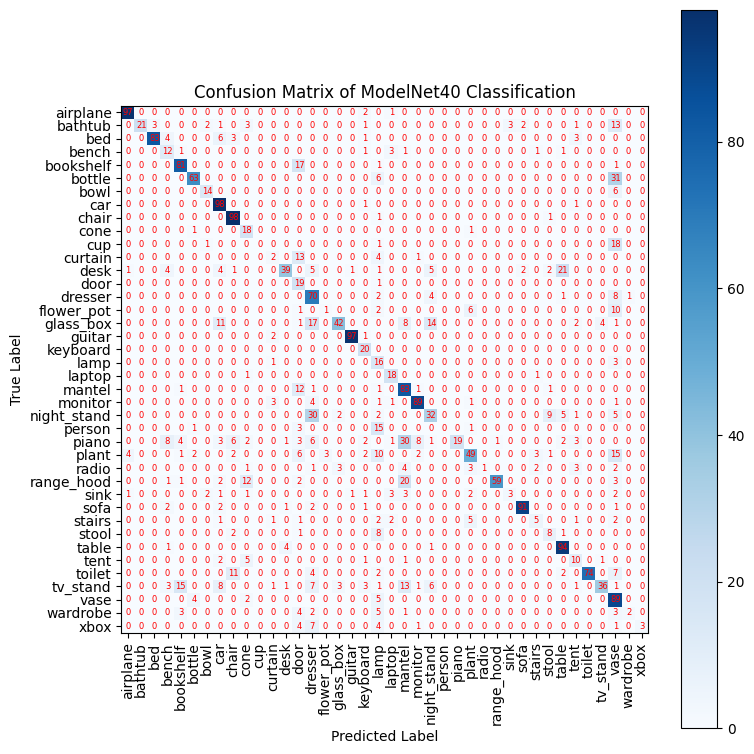

In [ ]:
# ✅ กำหนด device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ✅ ใส่ path ของโมเดลที่ต้องการโหลด
model_path = "/content/drive/MyDrive/Pointnet/models/dgcnn_model_512.pth"
assert os.path.exists(model_path), f"❌ ไม่พบไฟล์โมเดล: {model_path}"

# ✅ โหลดโมเดล
model_eval = DGCNN(num_classes=40).to(device)
model_eval.load_state_dict(torch.load(model_path, map_location=device))
model_eval.eval()

# ✅ Evaluate accuracy
total_correct = 0
total_test_samples = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for points, labels in test_loader:
        points, labels = points.to(device), labels.to(device)
        outputs = model_eval(points)
        preds = outputs.argmax(dim=1)
        total_correct += (preds == labels).sum().item()
        total_test_samples += labels.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_accuracy = total_correct / total_test_samples
print(f"✅ Test Accuracy = {test_accuracy:.4f}")

# ✅ Confusion Matrix
cm = confusion_matrix(all_labels, all_preds, labels=list(range(40)))
classes = test_dataset.classes

plt.figure(figsize=(8, 8))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title("Confusion Matrix of ModelNet40 Classification")
plt.colorbar()
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=90)
plt.yticks(tick_marks, classes)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# ใส่ตัวเลขในช่อง
for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center",
                 color="red", fontsize=6)

plt.tight_layout()
plt.show()


# Doble Model Train and use with DGCNN and Pointnet++ (Not finish)
เป็นไอเดียที่จริงๆโค้ดเสร็จแล้วแต่ดูจากเวลาที่ใช้ในการเทรนแล้ว runtime นาจะหมดก่อน เนื่องจากข้อมูลเยอะมากหลังทำการ Augment แล้วเทรน 2 โมเดลอีกจึงมาแค่โค้ด

## Load data with DGCNN Pointnet++

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class PointNetPlusPlus_768(nn.Module):
    def __init__(self, num_classes=40):
        super(PointNetPlusPlus_768, self).__init__()
        self.mlp1 = nn.Sequential(
            nn.Linear(3, 64), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Linear(64, 128), nn.BatchNorm1d(128), nn.ReLU()
        )
        self.mlp2 = nn.Sequential(
            nn.Linear(128, 256), nn.BatchNorm1d(256), nn.ReLU()
        )

        self.fc1 = nn.Linear(256, 256)
        self.bn1 = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256, 128)
        self.bn2 = nn.BatchNorm1d(128)
        self.fc3 = nn.Linear(128, num_classes)

    def forward(self, x):  # x: (B, 768, 3)
        B, N, _ = x.shape
        x = x.view(B * N, 3)
        x = self.mlp1(x)             # (B*N, 128)
        x = self.mlp2(x)             # (B*N, 256)
        x = x.view(B, N, 256)        # (B, 768, 256)
        x = x.max(dim=1)[0]          # (B, 256)
        x = F.relu(self.bn1(self.fc1(x)))
        x = F.relu(self.bn2(self.fc2(x)))
        return self.fc3(x)

## Ensemble predict

In [ ]:
import torch.nn.functional as F  # ยืนยันว่า import F แล้ว

def ensemble_predict(point_cloud_batch, model_pointnetpp, model_dgcnn, device):
    """
    ทำ Ensemble (Soft Voting) จาก PointNet++ และ DGCNN

    Parameters:
    - point_cloud_batch: Tensor of shape (B, N, 3)
    - model_pointnetpp: โมเดล PointNet++
    - model_dgcnn: โมเดล DGCNN
    - device: 'cuda' หรือ 'cpu'

    Returns:
    - pred_classes: Tensor ของ predicted class indices (B,)
    """
    model_pointnetpp.eval()
    model_dgcnn.eval()

    point_cloud_batch = point_cloud_batch.to(device)

    with torch.no_grad():
        logits1 = model_pointnetpp(point_cloud_batch)   # (B, num_classes)
        logits2 = model_dgcnn(point_cloud_batch)        # (B, num_classes)

        probs1 = F.softmax(logits1, dim=1)
        probs2 = F.softmax(logits2, dim=1)

        avg_probs = (probs1 + probs2) / 2.0             # Soft voting
        pred_classes = avg_probs.argmax(dim=1)          # (B,)

    return pred_classes.cpu()


## Train Doble Model

In [ ]:
!pip install -q tqdm

In [ ]:
# ✅ Imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import time

# ✅ Setup Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ✅ Configs
NUM_POINTS = 1024
BATCH_SIZE = 32
NUM_EPOCHS = 15   # ลดรอบเทรน
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
AUGMENTED_DIR = "/content/drive/MyDrive/Pointnet/ModelNet40_Augmented"

# ✅ Custom Dataset Class (โหลดจาก .npy)
class PointCloudDataset(Dataset):
    def __init__(self, root_dir, split='train', num_points=768, augment=True):
        self.root_dir = root_dir
        self.num_points = num_points
        self.augment = augment
        self.classes = sorted([d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))])
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(self.classes)}
        self.data = []

        for cls_name in self.classes:
            class_dir = os.path.join(root_dir, cls_name)
            if not os.path.isdir(class_dir):
                continue
            for fname in os.listdir(class_dir):
                if fname.endswith(".npy"):
                    if (split == 'train' and 'aug' in fname) or (split == 'train' and 'orig' in fname):
                        self.data.append((os.path.join(class_dir, fname), self.class_to_idx[cls_name]))
                    elif split == 'test' and 'orig' in fname:
                        self.data.append((os.path.join(class_dir, fname), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        file_path, label = self.data[idx]
        points = np.load(file_path)
        if points.shape[0] > self.num_points:
            indices = np.random.choice(points.shape[0], self.num_points, replace=False)
            points = points[indices]
        elif points.shape[0] < self.num_points:
            pad = self.num_points - points.shape[0]
            points = np.pad(points, ((0, pad), (0, 0)), mode='edge')
        return torch.tensor(points, dtype=torch.float32), torch.tensor(label, dtype=torch.long)

# ✅ Load Dataset
train_dataset = PointCloudDataset(AUGMENTED_DIR, split='train', num_points=NUM_POINTS, augment=True)
test_dataset = PointCloudDataset(AUGMENTED_DIR, split='test', num_points=NUM_POINTS, augment=False)

# ✅ Data Loaders (เพิ่ม worker)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

# ✅ สร้างโมเดลก่อนใช้ optimizer
model_pointnetpp = PointNetPlusPlus_Full1024(num_classes=len(train_dataset.classes)).to(DEVICE)
model_dgcnn = DGCNN(num_classes=len(train_dataset.classes)).to(DEVICE)

# ✅ Optimizers
optimizer_pp = torch.optim.Adam(model_pointnetpp.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
optimizer_dgcnn = torch.optim.Adam(model_dgcnn.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# ✅ Training Loop
history = {'epoch': [], 'pn_loss': [], 'pn_acc': [], 'dg_loss': [], 'dg_acc': []}

print(f"\n⏳ Start training for {NUM_EPOCHS} epochs...\n")
start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    model_pointnetpp.train()
    model_dgcnn.train()
    total_loss_pn, total_loss_dg = 0.0, 0.0
    correct_pn, correct_dg, total_samples = 0, 0, 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS}", leave=False)
    for points, labels in pbar:
        points = points.to(DEVICE)
        labels = labels.to(DEVICE)
        total_samples += points.size(0)

        optimizer_pp.zero_grad()
        optimizer_dgcnn.zero_grad()

        logits_pn = model_pointnetpp(points)
        logits_dg = model_dgcnn(points)

        loss_pn = F.cross_entropy(logits_pn, labels)
        loss_dg = F.cross_entropy(logits_dg, labels)

        loss_pn.backward()
        optimizer_pp.step()
        loss_dg.backward()
        optimizer_dgcnn.step()

        total_loss_pn += loss_pn.item() * points.size(0)
        total_loss_dg += loss_dg.item() * points.size(0)

        pred_pn = logits_pn.argmax(dim=1)
        pred_dg = logits_dg.argmax(dim=1)
        correct_pn += (pred_pn == labels).sum().item()
        correct_dg += (pred_dg == labels).sum().item()

        pbar.set_postfix({
            "PN loss": f"{loss_pn.item():.4f}",
            "DG loss": f"{loss_dg.item():.4f}"
        })

    avg_loss_pn = total_loss_pn / total_samples
    avg_loss_dg = total_loss_dg / total_samples
    train_acc_pn = correct_pn / total_samples
    train_acc_dg = correct_dg / total_samples

    history['epoch'].append(epoch)
    history['pn_loss'].append(avg_loss_pn)
    history['pn_acc'].append(train_acc_pn)
    history['dg_loss'].append(avg_loss_dg)
    history['dg_acc'].append(train_acc_dg)

    elapsed = (time.time() - start_time) / 60
    print(f"✅ Epoch {epoch:02d} completed | PN acc: {train_acc_pn:.4f} | DG acc: {train_acc_dg:.4f} | Time: {elapsed:.1f} min")

print("✅ Training finished.")


⏳ Start training for 15 epochs...



KeyboardInterrupt: 

## Save model and Predict with 2 model

In [ ]:
# ✅ Save both trained models (หลังเทรนเสร็จ)
SAVE_PATH_PP = "/content/drive/MyDrive/Pointnet/best_model_pointnetpp.pth"
SAVE_PATH_DGCNN = "/content/drive/MyDrive/Pointnet/best_model_dgcnn.pth"

torch.save(model_pointnetpp.state_dict(), SAVE_PATH_PP)
torch.save(model_dgcnn.state_dict(), SAVE_PATH_DGCNN)
print("✅ Models saved.")


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# ✅ เปลี่ยน path ตามที่คุณเซฟไว้
LOAD_PATH_PP = "/content/drive/MyDrive/Pointnet/best_model_pointnetpp.pth"
LOAD_PATH_DGCNN = "/content/drive/MyDrive/Pointnet/best_model_dgcnn.pth"

# ✅ โหลดโมเดลกลับมา
model_pointnetpp.load_state_dict(torch.load(LOAD_PATH_PP))
model_dgcnn.load_state_dict(torch.load(LOAD_PATH_DGCNN))
model_pointnetpp.eval()
model_dgcnn.eval()

# ✅ ฟังก์ชัน ensemble_predict ต้องถูกนิยามไว้ก่อนหน้านี้แล้ว

# ✅ Evaluate บน test set
all_preds = []
all_labels = []

for points, labels in test_loader:
    preds = ensemble_predict(points, model_pointnetpp, model_dgcnn, DEVICE)
    all_preds.extend(preds.numpy())
    all_labels.extend(labels.numpy())

# ✅ Accuracy
acc = accuracy_score(all_labels, all_preds)
print(f"\n✅ Ensemble Accuracy on test set: {acc:.4f}")

# ✅ Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=test_dataset.classes)
fig, ax = plt.subplots(figsize=(12, 12))
disp.plot(ax=ax, xticks_rotation=90, cmap='Blues')
plt.title("Confusion Matrix - Ensemble Prediction")
plt.tight_layout()
plt.show()
